# Markov Chain Monte Carlo

Monte Carlo methods are computational algorithms that rely on random sampling to obtain numerical results. See [last week](./11a_MC.ipynb).

Markov Chains are stochastic processes in which the probability of each event depends only the state attained in the previous event. ex: Random Walk

Markov Chain Monte Carlo (MCMC) describe a class of algorithms that iteratively draw samples from a probability distribution approaching an equilibrium distribution with each step. 

Main Applications:
+ Simulation of probabilistic physical processes (like statistical mechanics, etc.)
+ Bayesian inference for model fitting



## Markov Process

A Markov Process is described by:
1. A set of states $S = s_1, s_2, s_3, \ldots$
2. A transition function $T(s_i, s_j)$ which describes the probability that a process in state $s_i$ transitions to state $s_j$. 

Say you have an initial state $X_i$, the next state $X_{i+1}$ is drawn from a probability distribution defined by $T(X_i)$. *Markov processes are defined as memory-less by this metric*

If you wanted to directly compute the underlying distribution function ${\bf P}(n,s)$ after $n$ steps, you'd need to calculate a total probability:

$$ P(0,s) \cdot T^n $$

where $T$ is a probability matrix, in which $T_{ij}$ describes the transition function from $s_i$ to $s_j$. This requires $\mathcal{O}(\log n)$ matrix multiplications. 

With MCMC, you start with some initial state vector and iterate and update the next state according to $T(s_i,s_j)$ some number $n$ times. If you repeat this $k$ times then you will have drawn $k$ samples from the underlying distribution $P(n,s)$. 

If you take enough steps, the underlying distribution should approach some equilibrium stationary distribution independent of the number of steps taken or the initial state $$\lim_{n \rightarrow \infty} P(n,s) \rightarrow P_s$$ (given [some conditions](https://en.wikipedia.org/wiki/Markov_chain#Stationary_distribution_on_finite_state_space) on the transition matrix T)

In general the transition matrix must satisy:
$$\sum_j T_{ij} = 1$$


(array([0.   , 0.   , 0.   , 0.004, 0.002, 0.008, 0.032, 0.05 , 0.098,
        0.16 , 0.146, 0.152, 0.158, 0.088, 0.052, 0.032, 0.016, 0.002,
        0.   , 0.   ]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5,
        10.5, 11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5]),
 <BarContainer object of 20 artists>)

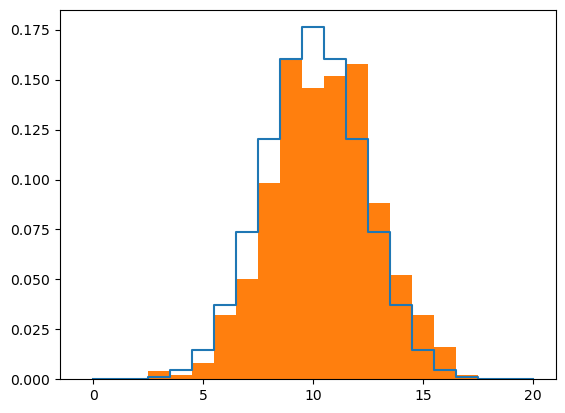

In [70]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng
from math import factorial
rng = default_rng()

def MarkovChain(s0,k,p,steps):
    ps = np.array([])
    for i in np.arange(steps):
        svals = []
        s = s0
        for kk in k:
            if rng.random() <= p:
                s = 1
            else:
                s = 0
            svals.append(s)
        ps = np.append(ps,np.sum(svals))
    return ps

    

def binomial(k,n,p):
    k = k.astype(int)
    nchoosek = factorial(n) / np.array([factorial(kk)*factorial(n-kk) for kk in k]) 
    return nchoosek * p**k * (1.-p)**(n-k) 


# 20 coin flips
ph = 0.5
k = np.arange(0,21,1,dtype=int)
plt.step(k,binomial(k,20,ph),where='mid')
plt.hist(MarkovChain(1,k,ph,500),density=True,bins=np.arange(-0.5,20.5,1))


## Metropolis Algorithm
The Metropolis Algorithm is a type of MCMC method in which we can use MCMC to sample from an underlying distribution.
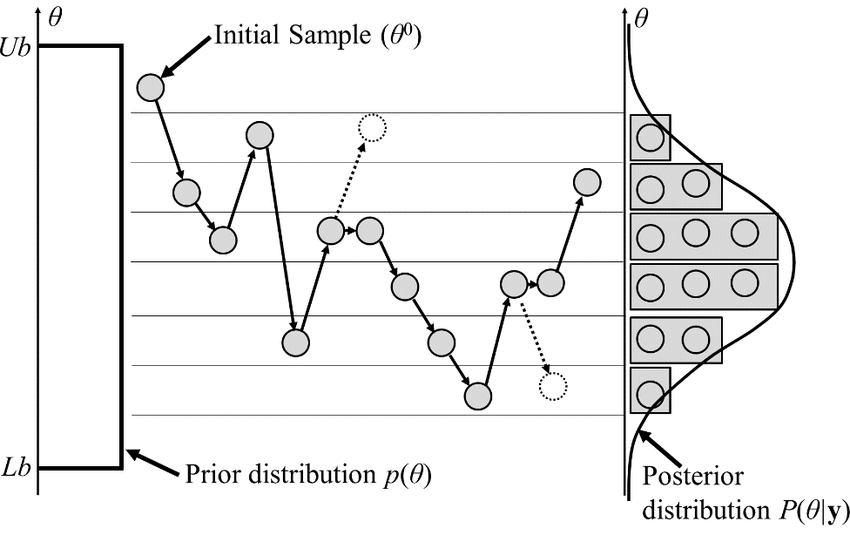

For example, many times we want to extract the expected value of some quantity $X_i$ whose behavior is governed by probability $P_i$. 
We know the expectation value of a quantity is just the integral with it's probability density function:
$$ <X> = \int X P dk $$

We can use what we learned about *importance sampling* [last week](./11a_MC.ipynb) to rerrange this in terms of a weighted average:

$$ <X> = \left < \frac{X_i P_i}{w_i}\right >_w \sum_i w_i$$

which we can re-state in terms of the average of samples $X_k$ drawn from the underlying distribution $P$:

$$<X> \simeq \frac{1}{N} \sum_{k=1}^N X_k$$

by assuming that $w_i = P_i$. If the weights are the probabilities, that means we are **importance sampling in regions of the parameter space precisely where probabilities are high**

In practice, knowing and describing the underlying PDF can very difficult! 

We can use a Markov Process to help us calculate the average state-dependent behavior of some system if we can describe its transition probablity between states in such a fashion that reflects some complicated underlying probability distribution, without explicitly defining the underlying PDF. 

This can be incredibly efficient for multi-dimensional problems with complicated parameter spaces. 

```{note}Sample Metropolis-Hastings Scheme
1. Choose an initial state $s_0 = s_i$
2. Choose a move at random to another state $s_j$ from an allowed set of moves. 
3. Calculate the acceptance probability for the move to the new state based on the acceptance ratio of the transition probability. 
$$ A(s_j,s_i) = \min\left ( 1, \frac{T_{ij}}{T_{ji}} \right ) $$
4. Accept or reject the move to the new state $j$ by drawing a uniform random number and comparing to the probability.
5. Update average of the quantity of interest.
6. Iterate from step 2. 
```

### Ex: Statistical Mechanics
(See: Newman 10.3.2 for an alternative explanation)

The original Metropolis-Hastings algorithm was used for statistical mechanics problems in which the physics is governed by the Boltzmann distribution, where:
$$ P(E_i) = \frac{e^{-\beta E_i}}{Z} $$

where $\beta = \frac{1}{k_b T}$  and $Z$ is the [partition function](https://en.wikipedia.org/wiki/Partition_function_(statistical_mechanics)):

$$ Z = \sum_i e^{-\beta E_i} $$

which describes how probabilities are distributed across all the various states.

You may recall from your statistical mechanics courses, that partition functions can get notoriously difficult to compute for different kinds of assemblages of particles and additional degrees of freedom. 

So instead, we can construct our acceptance probability based on the ratio of the transition probabilities from one state to the other. 

$$ \frac{T_{ij}}{T_{ji}} = \frac{P(E_j)}{P(E_i)} = e^{-\beta(E_j - E_i)}$$

Note, that this construction removes the dependence on the partition function $Z$ (yay!).

This makes sense because the acceptance probability only needs to know which of the two states are more likely in order to choose the more favorable state, not their absolute probabilities relative to all possible states.

You can infer that by iteratively making moves, comparing our current state to the next possible state, and moving to the more probable one, we can eventually find the most probable state, (thereby achieving equilibrium). 

### Ex: Internal Energy of an Ideal Gas
Let's say we have an ideal gas of $N$ atoms at some temperature $T$ in a box of width $L$.

An atom's energy should satisfy the Schrodinger equation:
$$ -\frac{\hbar^2}{2m} \frac{\partial^2 \psi}{\partial x^2} = E\psi(x)$$

Recall, that in one dimension for a single particle of mass $m$:
$$ E_n = \frac{\pi^2\hbar^2}{2mL^2}n^2$$

So in three dimensions, 
$$ E(n_x, n_y, n_z) = \frac{\pi^2\hbar^2}{2mL^2} (n_x^2 + n_y^2 + n_z^2)$$

Thus the total energy over all particles is:

$$ E = \sum_{i=1}^N E_i(n_x, n_y, n_z) $$

With the probability of occupying state $E_i$ given by the Boltzmann distribution. 



<h2><span class="fa fa-flash"></span> In-Class Coding Exercise </h2>

```{embed} icc_12-1
```

## MCMC: Simulated Annealing



<h2><span class="fa fa-flash"></span> In-Class Coding Exercise </h2>

```{embed} icc_12-2
```